Preamble

In [5]:
import numpy as np 
import pandas 
import matplotlib
import matplotlib.pyplot as plt
Data = pandas.read_csv("data.csv")


MADS

DAVID

In [8]:
# Create the dummy as a column in Data
Data["madsk"] = (Data["past_employment"] > 3).astype(int)
Data["past_employment^2"] = Data["past_employment"] ** 2
Data["past_employment^3"] = Data["past_employment"] ** 3
import statsmodels.formula.api as smf

# Estimate the regression
regression = smf.ols(
    "ui_duration ~ madsk * (past_employment + I(past_employment**2) + I(past_employment**3))",
    data=Data
).fit()

print(regression.summary())

# Save fitted values
Data["predicted_ui_duration"] = regression.predict(Data)

# Create bins
Data["employment_bin"] = pandas.cut(
    Data["past_employment"],
    bins=30
)

# Collapse into bin means
binned_data = (
    Data
    .groupby(["employment_bin", "madsk"], observed=True)
    .agg(
        past_employment=("past_employment", "mean"),
        ui_duration=("ui_duration", "mean")
    )
    .reset_index()
)

display(binned_data.head())

                            OLS Regression Results                            
Dep. Variable:            ui_duration   R-squared:                       0.968
Model:                            OLS   Adj. R-squared:                  0.968
Method:                 Least Squares   F-statistic:                 8.774e+05
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        09:59:34   Log-Likelihood:                 55570.
No. Observations:              200000   AIC:                        -1.111e+05
Df Residuals:                  199992   BIC:                        -1.110e+05
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                                    coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept     

,employment_bin,madsk,past_employment,ui_duration
0,"(0.0186, 0.224]",0,0.163223,5.076241
1,"(0.224, 0.423]",0,0.330854,4.625194
2,"(0.423, 0.622]",0,0.523327,4.161642
3,"(0.622, 0.821]",0,0.720288,3.744232
4,"(0.821, 1.02]",0,0.920041,3.373754


C:\Users\david\AppData\Local\Temp\ipykernel_39444\2763936192.py:49: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


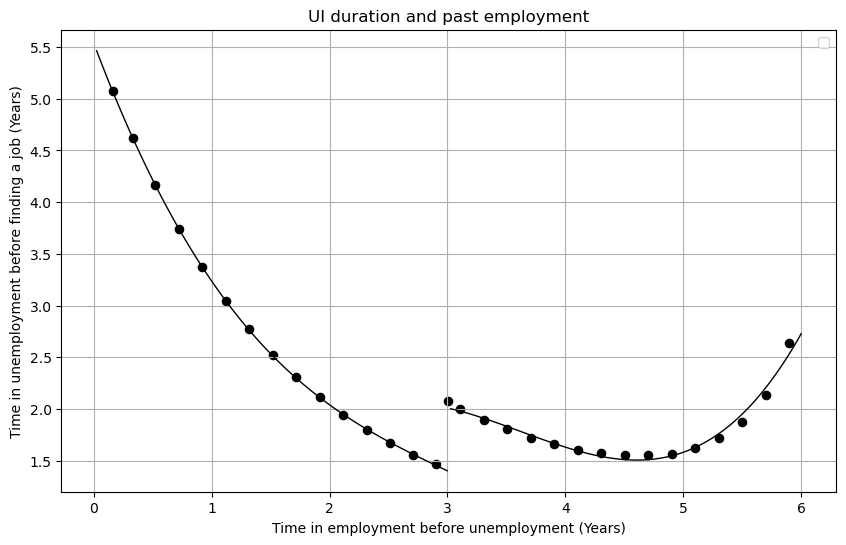

In [10]:
plt.figure(figsize=(10, 6))

# Binned means as dots
for dummy_value in sorted(binned_data["madsk"].unique()):
    subset = binned_data[binned_data["madsk"] == dummy_value]

    plt.scatter(
        subset["past_employment"],
        subset["ui_duration"],
        color="black",
        s=35,
    )

# Smooth prediction grid
employment_grid = np.linspace(
    Data["past_employment"].min(),
    Data["past_employment"].max(),
    200
)

# Regression predictions
for dummy_value in sorted(Data["madsk"].unique()):

    if dummy_value == 0:
        employment_grid_cut = employment_grid[employment_grid <= 3]
    else:
        employment_grid_cut = employment_grid[employment_grid >= 3]

    prediction_data = pandas.DataFrame({
        "past_employment": employment_grid_cut,
        "madsk": dummy_value
    })

    prediction_data["predicted_ui_duration"] = regression.predict(
        prediction_data
    )

    plt.plot(
        prediction_data["past_employment"],
        prediction_data["predicted_ui_duration"],
        linewidth=1,
        color="black",
    )

plt.xlabel("Time in employment before unemployment (Years)")
plt.ylabel("Time in unemployment before finding a job (Years)")
plt.title("UI duration and past employment")
plt.grid(True)
plt.legend()
plt.show()